# 00 — Hakaluki Haor user-supplied boundary and Earth Engine setup

Uses `Study area/Hakaluki_Haor.shp` and its companion files. The shapefile is **user supplied, not independently verified**. Audit its coordinates, extent and provenance before final publication. No new boundary will be downloaded from GitHub by this notebook.


## A. One-time install and authentication

In a terminal from the project root run: `pip install -r requirements.txt`. You must register a Google Cloud project for Earth Engine and place its project ID in `config/settings.json`. GEE credentials are obtained interactively when the notebook connects. Do not commit credentials to Git.

In [1]:
from pathlib import Path
import os, sys, json
import pandas as pd
import geopandas as gpd
from IPython.display import display

ROOT = Path(r"F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project")
assert (ROOT / 'config/settings.json').exists(), 'Start Jupyter in project root or notebooks/.'
sys.path.insert(0, str(ROOT))
from src.hakaluki_core import (project_paths,download_candidate_boundary,load_boundary,
    boundary_audit,export_candidate_geojson,make_boundary_reference_figure)
from src.ee_pipeline import initialize,geometry_from_geodataframe,s1_collection,CH4_ID,CH4_BAND
import ee
PATHS = project_paths(ROOT)
CFG = json.loads((ROOT / 'config/settings.json').read_text())
print('Project:', ROOT)
print('Boundary status in configuration:', CFG['study_area_status'])

Project: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project
Boundary status in configuration: USER_SUPPLIED_UNVERIFIED


## B. Audit your Hakaluki Haor shapefile

The polygon is read directly from `Study area/Hakaluki_Haor.shp`, checked for CRS and geometry, and saved to `data/boundary/hakaluki_analysis_candidate.geojson` for the other notebooks. The presence of a GIS file does not establish whether it represents the full haor, a protected-area boundary, or a seasonal inundation footprint.


In [2]:
# Load the shapefile YOU supplied; do not silently download another boundary.
local_shp = ROOT / 'Study area' / 'Hakaluki_Haor.shp'
assert local_shp.exists(), f'Study-area shapefile not found: {local_shp}'
boundary_source = local_shp
source_status = 'user-supplied boundary; geometry and provenance NOT independently verified'
GDF = load_boundary(boundary_source)
AUDIT = boundary_audit(GDF)
AUDIT['source_file'] = str(boundary_source)
AUDIT['source_status'] = source_status
AUDIT['provenance'] = 'User-supplied Hakaluki_Haor.shp; independently verify original source.'
print(json.dumps(AUDIT, indent=2))
(PATHS['boundary'] / 'boundary_audit.json').write_text(json.dumps(AUDIT, indent=2))
export_candidate_geojson(GDF, PATHS['boundary'] / 'hakaluki_analysis_candidate.geojson')
make_boundary_reference_figure(GDF, PATHS['maps'] / '01_boundary_audit_candidate.png')
display(GDF.head())


{
  "area_km2": 172.291,
  "reference_area_km2": 181.15,
  "area_ratio_to_reference": 0.951,
  "bounds_wgs84": [
    91.9524,
    24.57815,
    92.12167,
    24.73476
  ],
  "overlaps_reference_envelope": true,
  "feature_count": 1,
  "provenance": "User-supplied Hakaluki_Haor.shp; independently verify original source.",
  "source_file": "F:\\Wetland Test\\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\\Study area\\Hakaluki_Haor.shp",
  "source_status": "user-supplied boundary; geometry and provenance NOT independently verified"
}


,OBJECTID_1,OBJECTID,FID_Haor_s,HAOR_SYTM,HAOR_NAME,AREA_SQKM,AREA_HA,COMMENTS,TYPE,EIH,...,Class_name,Shape_Leng,InPoly_FID,Shape_Le_1,Remarks,SmoPgnFlag,area,Shape_Le_2,Shape_Area,geometry
0,422,10179,20,Hakaluki Haor,Hakaluki Haor,173.016432,17301.643155,Listed (205),Foothill,1,...,Water,823560.0,332,131610.552451,JIM,0,0.0,156553.681805,1.722907e+08,"POLYGON ((92.00113 24.6262, 92.00099 24.62613,..."


Review the outline and its GIS metadata; the government-reported 181.15 km² refers to a specified wetland area and may not match a polygon representing a different habitat or seasonal state. An area difference requires investigation, not automatic resizing.

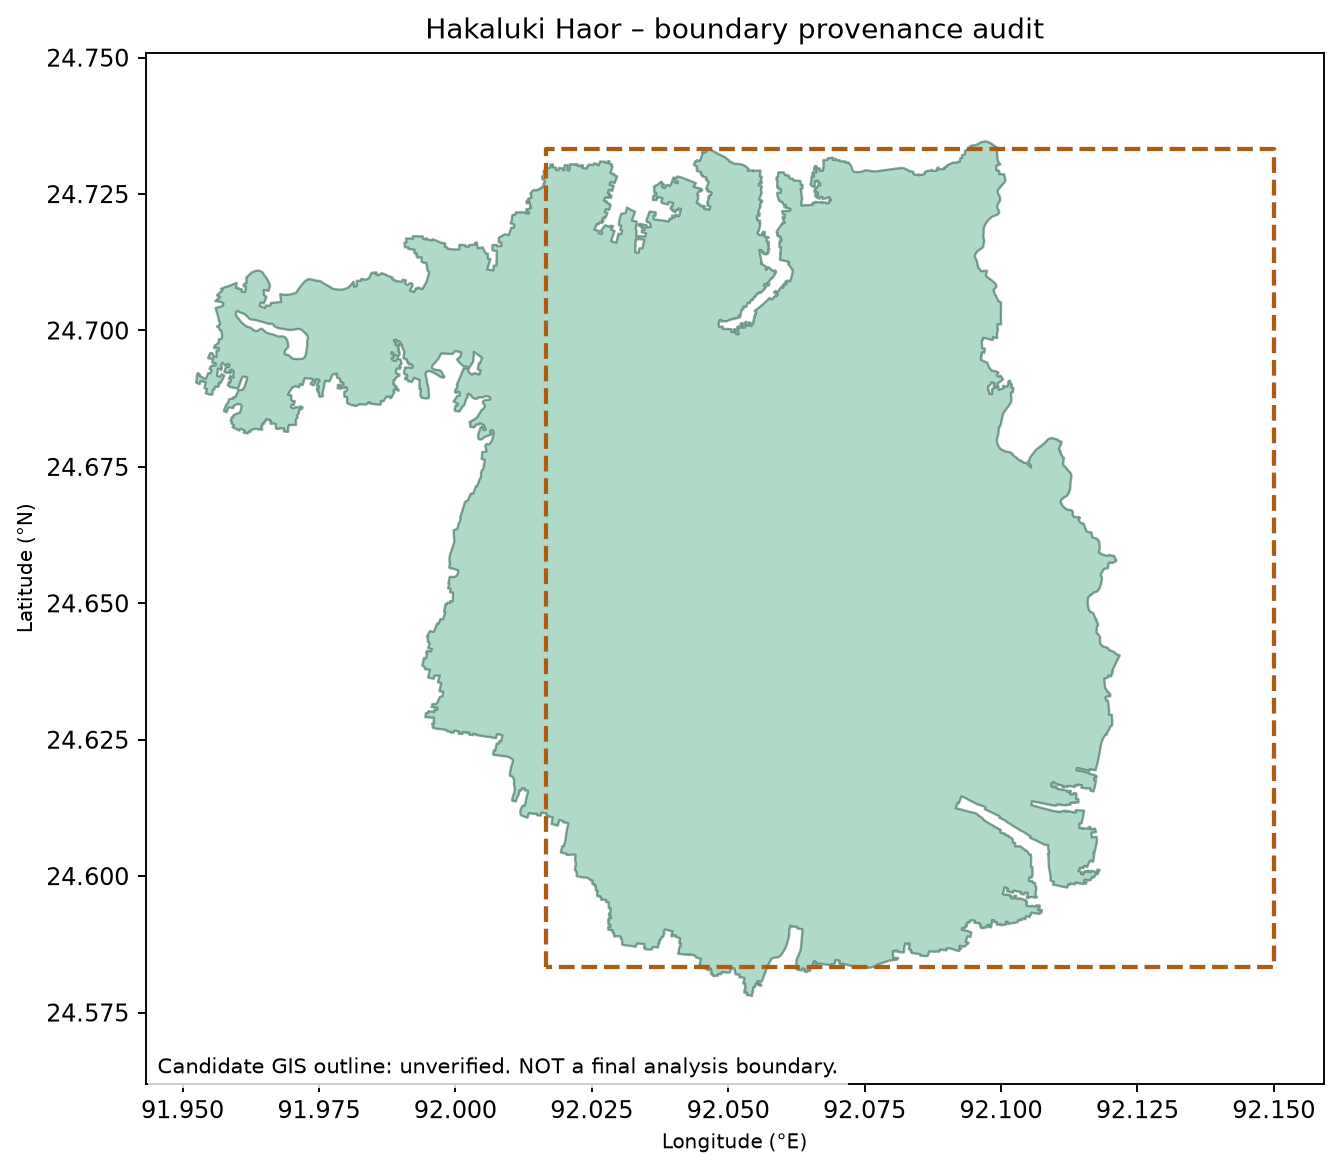

In [3]:
from IPython.display import Image
Image(filename=str(PATHS['maps']/'01_boundary_audit_candidate.png'))

In [4]:

# Hakaluki Haor boundary validation

print("Original CRS:", GDF.crs)
print("Number of features:", len(GDF))

print("Geometry valid:", GDF.geometry.is_valid.all())
print("Geometry empty:", GDF.geometry.is_empty.any())

# Reproject to UTM Zone 46N
gdf_utm = GDF.to_crs(epsg=32646)

# Calculate actual polygon area
calculated_area = gdf_utm.geometry.area.sum() / 1_000_000

print("\nCalculated area (km²):", round(calculated_area, 4))
print("Shapefile AREA_SQKM:", GDF["AREA_SQKM"].iloc[0])

print("\nGeographic bounds (WGS84):")
print(GDF.to_crs(epsg=4326).total_bounds)


Original CRS: EPSG:4326
Number of features: 1
Geometry valid: True
Geometry empty: False

Calculated area (km²): 172.2907
Shapefile AREA_SQKM: 173.016431551

Geographic bounds (WGS84):
[91.9523999  24.57814562 92.12166606 24.73475819]


## C. Connect to GEE and inspect observation availability

The next cell only connects when your Earth Engine project ID is configured. GEE OAuth may open a login prompt. The 2022 counts are **number of GEE image/tile items intersecting geometry**, not guaranteed usable observations after cloud and quality screening.

In [5]:

# Initialize Google Earth Engine
initialize(CFG["earth_engine_cloud_project"])

# Convert Hakaluki Haor boundary to GEE geometry
ROI = geometry_from_geodataframe(GDF)

# Sentinel-1 collection
S1 = s1_collection(
    ROI,
    "2022-01-01",
    "2023-01-01"
)

# Sentinel-2 collection
S2 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(ROI)
    .filterDate("2022-01-01", "2023-01-01")
)

# Sentinel-5P methane collection
S5P = (
    ee.ImageCollection(CH4_ID)
    .filterBounds(ROI.buffer(CFG["ch4_buffer_m"]))
    .filterDate("2022-01-01", "2023-01-01")
)

# Check satellite observation availability
print("2022 intersecting collection item counts:")

print("Sentinel-1:", S1.size().getInfo())
print("Sentinel-2:", S2.size().getInfo())
print("TROPOMI CH4:", S5P.size().getInfo())


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


2022 intersecting collection item counts:
Sentinel-1: 57
Sentinel-2: 290
TROPOMI CH4: 4667


## D. Interactive geometry review

This preview uses satellite composites for visual checking only, not class validation. `geemap` uses an interactive map within Jupyter.

In [6]:
import geemap
M=geemap.Map()
M.centerObject(ROI,11)
M.addLayer(ROI, {'color':'ff7a00'}, 'Candidate boundary – verify before publishing')
M.addLayer(ee.Image('JRC/GSW1_4/GlobalSurfaceWater').select('occurrence'),
           {'min':0,'max':100,'palette':['white','#4c8fd9','#123777']},'JRC occurrence through 2021')
M

Map(center=[24.65919068595402, 92.05303257798609], controls=(WidgetControl(options=['position', 'transparent_b…

## Output checklist

- `data/boundary/hakaluki_analysis_candidate.geojson` — boundary under review
- `data/boundary/boundary_audit.json` — area and envelope QC metadata
- `results/maps/01_boundary_audit_candidate.png` — QA map

**Do not** publish candidate-boundary wetland statistics as final without boundary verification.

In [7]:

from pathlib import Path
from datetime import datetime, timezone
from pyproj import Geod
import json

PROJECT_DIR = Path(
    r"F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project"
)

boundary_dir = PROJECT_DIR / "data" / "boundary"
boundary_dir.mkdir(parents=True, exist_ok=True)

# Original geographic geometry
boundary = GDF.to_crs("EPSG:4326").copy()

# Calculate projected area
utm = boundary.to_crs("EPSG:32646")
utm_area_km2 = utm.geometry.area.sum() / 1e6

# Independently calculate ellipsoidal/geodesic area
geod = Geod(ellps="WGS84")
geodesic_area_km2 = sum(
    abs(geod.geometry_area_perimeter(geom)[0])
    for geom in boundary.geometry
) / 1e6

# Save study boundary as GeoPackage and GeoJSON
boundary.to_file(
    boundary_dir / "hakaluki_boundary.gpkg",
    layer="hakaluki_boundary",
    driver="GPKG"
)

boundary.to_file(
    boundary_dir / "hakaluki_boundary.geojson",
    driver="GeoJSON"
)

metadata = {
    "study_area": "Hakaluki Haor",
    "source": "User-provided shapefile",
    "source_crs": str(GDF.crs),
    "analysis_crs": "EPSG:32646",
    "geometry_valid": bool(GDF.geometry.is_valid.all()),
    "projected_area_km2": float(utm_area_km2),
    "geodesic_area_km2": float(geodesic_area_km2),
    "stored_attribute_area_km2": float(
        GDF["AREA_SQKM"].iloc[0]
    ),
    "bounds_wgs84": boundary.total_bounds.tolist(),
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "validation_status": "geometry_passed_source_unverified"
}

with open(
    boundary_dir / "boundary_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=4)

print("Boundary saved successfully.")
print(f"Projected area: {utm_area_km2:.4f} km²")
print(f"Geodesic area: {geodesic_area_km2:.4f} km²")
print("Output directory:", boundary_dir)


Boundary saved successfully.
Projected area: 172.2907 km²
Geodesic area: 172.3895 km²
Output directory: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\data\boundary
